In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [2]:
from __future__ import division
import matplotlib.pyplot as plt
from deltasigma import *
import numpy as np
from IPython.core.display import Image
import numpy as np, pandas as pd

#from turtle import title
from matplotlib import text

from itertools import zip_longest as izip_longest
from scipy.signal import tf2zpk
from scipy.signal import lfilter


In [3]:
class Table(list):
    def _repr_html_(self):
        html = ["<table>"]
        for row in self:
            html.append("<tr>")
            for col in row:
                try:
                    float(col)
                    html.append("<td>%.6f</td>" % col)
                except(ValueError):
                    html.append("<td><b>%s</b></td>" % col)
            html.append("</tr>")
        html.append("</table>")
        return ''.join(html)

def zpk_multiply(a, b):
    za, pa, ka = ds._utils._get_zpk(a)
    zb, pb, kb = ds._utils._get_zpk(b)
    pa = pa.tolist() if hasattr(pa, 'tolist') else pa
    pb = pb.tolist() if hasattr(pb, 'tolist') else pb
    za = za.tolist() if hasattr(za, 'tolist') else za
    zb = zb.tolist() if hasattr(zb, 'tolist') else zb
    return ds.cancelPZ((za+zb, pa+pb, ka*kb))

Synthesized a 4-order NTF, with roots:

 Zeros:			 Poles:
                    (z - 1)^4                    
-------------------------------------------------
 (z^2 - 1.207z + 0.3789) (z^2 - 1.433z + 0.6598) 


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:85: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  hold_status = plt.ishold()
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:90: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed

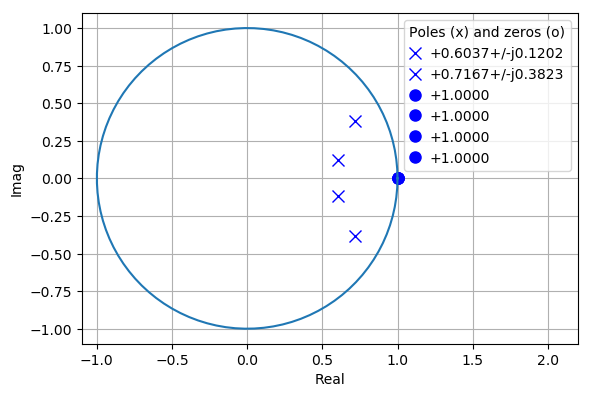

In [4]:
order = 4
osr = 8
nlev = 8
Hinf = 2
form = 'CRFBD'

ntf = synthesizeNTF(order, osr, H_inf=Hinf) 
print ("Synthesized a %d-order NTF, with roots:\n" % order)
print (" Zeros:\t\t\t Poles:")      
print (pretty_lti(ntf))
plotPZ(ntf, markersize=8, showlist=True)

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:85: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  hold_status = plt.ishold()
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:90: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed

Synthesized a 4-order NTF, with roots:

        (z^2 - 1.891z + 0.9999) (z - 1)^2        
-------------------------------------------------
 (z^2 - 1.463z + 0.5433) (z^2 - 1.678z + 0.7741) 


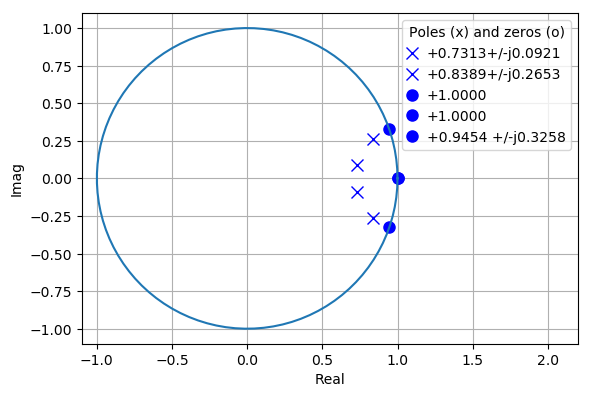

In [24]:
order = 4
osr = 8
nlev = 8
f0 = 0.25
Hinf = 1.5
ntf = synthesizeNTF(order, osr, 2, Hinf)   
plotPZ(ntf, markersize=8, showlist=True)
print ("Synthesized a %d-order NTF, with roots:\n" % order)   
print (pretty_lti(ntf))

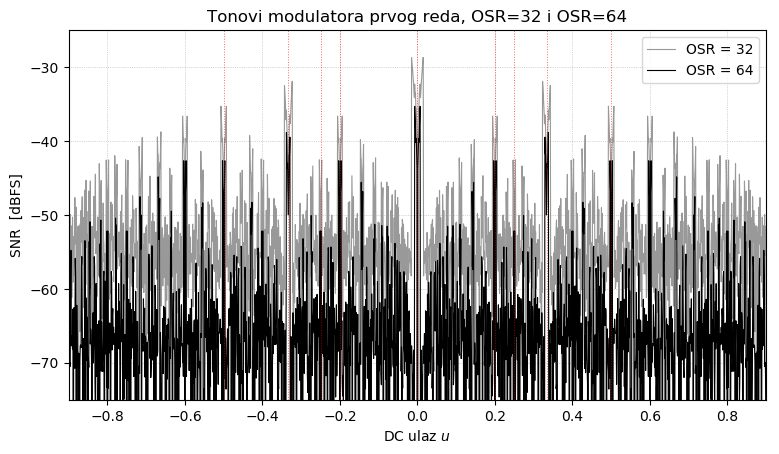

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import rfft

N  = 1 << 14                       # duzina simulacije po tacki
us = np.linspace(-0.9, 0.9, 1801)  # jednosmerni ulazi

# --- MOD1 za SVE vrednosti u odjednom (vektorizovano po u) ---
y = np.zeros_like(us)
v = np.empty((N, us.size))
for k in range(N):
    vv   = np.where(y >= 0, 1.0, -1.0)   # sgn, uz v=+1 kad je y=0
    v[k] = vv
    y   += us - vv                       # jednacina 2.21

# --- spektar, normalizovan na punu skalu (dBFS) ---
win  = 0.5*(1 - np.cos(2*np.pi*np.arange(N)/N))          # Hann
spec = np.abs(rfft(v*win[:, None], axis=0) / (N/4))**2   # sinus pune skale -> 0 dB

fig, ax = plt.subplots(figsize=(9, 4.8))
for osr, col in ((32, '0.6'), (64, 'k')):
    fB = int(np.floor(N/(2*osr)))
    p  = 10*np.log10(spec[3:fB+1].sum(axis=0) + 1e-30)   # bin 0..2 = DC = signal
    ax.plot(us, p, color=col, lw=0.8, label=f'OSR = {osr}')

for r in (0, 0.5, -0.5, 1/3, -1/3, 0.25, -0.25, 0.2, -0.2):
    ax.axvline(r, color='r', ls=':', lw=0.7, alpha=0.6)

ax.set_xlim(-0.9, 0.9); ax.set_ylim(-75, -25)
ax.set_xlabel('DC ulaz $u$')
ax.set_ylabel('SNR  [dBFS]')
ax.set_title('Tonovi modulatora prvog reda, OSR=32 i OSR=64')
ax.grid(ls=':', lw=0.5); ax.legend(loc='upper right')
plt.show()